# Workshop 3: MNIST feed-forward example

Classify 28 by 28 grayscale images of handwritten digits into ten classes (0-9).
The workflow is **inspect -> preprocess -> build -> train -> evaluate**.
Run the notebook from top to bottom using the environment in the root README.
The dataset is downloaded by Keras on its first use.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras.datasets import mnist
from keras import models, layers
from keras.utils import to_categorical

keras.utils.set_random_seed(42)

## 1. Load and inspect the images

There are 60,000 training examples and 10,000 test examples. Keep the raw arrays
separate from the processed arrays so rerunning preprocessing does not scale
pixels or encode labels twice.

Training: (60000, 28, 28) (60000,)
Test:     (10000, 28, 28) (10000,)


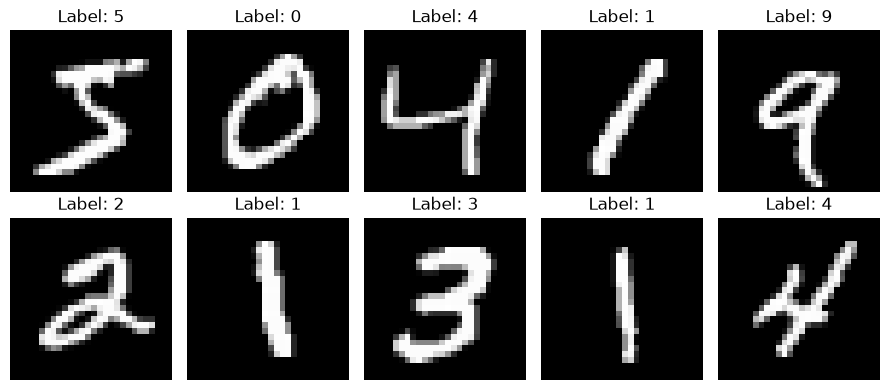

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print('Training:', x_train.shape, y_train.shape)
print('Test:    ', x_test.shape, y_test.shape)

fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap='gray')
    ax.set_title(f'Label: {y_train[i]}')
    ax.axis('off')
fig.tight_layout()
plt.show()

## 2. Prepare the inputs and targets

Flatten each image to 784 inputs and scale pixels from 0-255 to 0-1 as `float32`.
One-hot encoding changes a label such as 2 into `[0, 0, 1, 0, ...]`.
This matches the ten softmax outputs and `categorical_crossentropy` loss.

In [3]:
train_images = x_train.reshape(len(x_train), -1).astype('float32') / 255.0
test_images = x_test.reshape(len(x_test), -1).astype('float32') / 255.0
train_labels = to_categorical(y_train, num_classes=10).astype('float32')
test_labels = to_categorical(y_test, num_classes=10).astype('float32')
print('Input shape:', train_images.shape, 'range:', train_images.min(), train_images.max())
print('Label shape:', train_labels.shape)
print('Example:', y_train[5], '->', train_labels[5])

Input shape: (60000, 784) range: 0.0 1.0
Label shape: (60000, 10)
Example: 2 -> [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]


## 3. Build and compile the network

`Dense(512, relu)` learns features from the 784 pixel values. The final softmax
returns ten probabilities that sum to one. There are 407,050 trainable parameters:
`784 * 512 + 512` in the hidden layer and `512 * 10 + 10` in the output layer.
RMSprop updates the weights to minimise categorical cross-entropy.

In [4]:
keras.utils.set_random_seed(42)
network = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(512, activation='relu'),
    layers.Dense(10, activation='softmax'),
])
network.summary()
network.compile(optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
                loss='categorical_crossentropy', metrics=['accuracy'])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Train for five epochs

An epoch is one pass over the training subset. A batch of 128 examples is used
for each weight update. Reserve 20% of the original training set for validation;
validation examples are evaluated after each epoch and do not update weights.
The separate test set remains unused until the final evaluation.

In [5]:
history = network.fit(train_images, train_labels, epochs=5, batch_size=128,
                      validation_split=0.2, verbose=2)

Epoch 1/5
375/375 - 1s - 2ms/step - accuracy: 0.9166 - loss: 0.2926 - val_accuracy: 0.9597 - val_loss: 0.1457
Epoch 2/5
375/375 - 1s - 1ms/step - accuracy: 0.9646 - loss: 0.1217 - val_accuracy: 0.9693 - val_loss: 0.1058
Epoch 3/5
375/375 - 1s - 1ms/step - accuracy: 0.9773 - loss: 0.0790 - val_accuracy: 0.9719 - val_loss: 0.0927
Epoch 4/5
375/375 - 1s - 2ms/step - accuracy: 0.9844 - loss: 0.0558 - val_accuracy: 0.9749 - val_loss: 0.0866
Epoch 5/5
375/375 - 1s - 2ms/step - accuracy: 0.9896 - loss: 0.0403 - val_accuracy: 0.9767 - val_loss: 0.0836


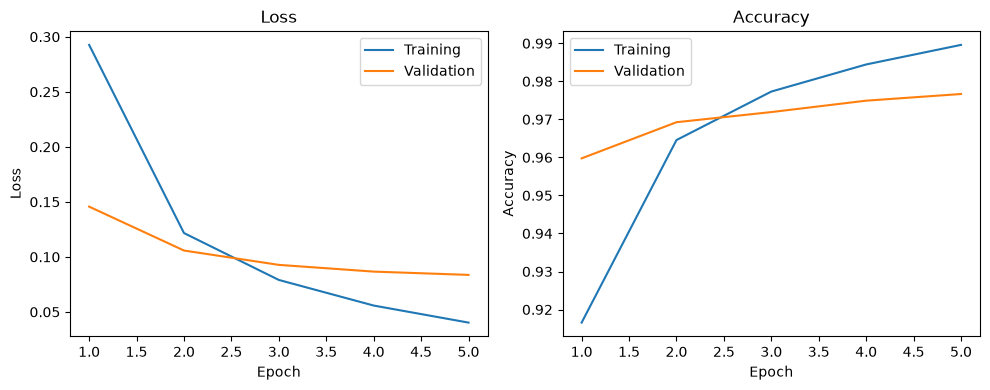

In [6]:
epochs = range(1, len(history.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, ['loss', 'accuracy']):
    ax.plot(epochs, history.history[metric], label='Training')
    ax.plot(epochs, history.history['val_' + metric], label='Validation')
    ax.set(xlabel='Epoch', ylabel=metric.capitalize(), title=metric.capitalize())
    ax.legend()
fig.tight_layout()
plt.show()

## 5. Evaluate on unseen test data

Accuracy is the fraction of correctly classified images. Loss also measures how
confident the predictions are. Training accuracy alone is not a generalisation score.

In [7]:
test_loss, test_acc = network.evaluate(test_images, test_labels, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.2%}')
probabilities = network.predict(test_images[:10], verbose=0)
print('Predicted:', np.argmax(probabilities, axis=1))
print('Actual:   ', y_test[:10])

Test loss: 0.0768
Test accuracy: 97.60%
Predicted: [7 2 1 0 4 1 4 9 5 9]
Actual:    [7 2 1 0 4 1 4 9 5 9]


## Reflection

The model learns to recognise digits using only dense layers. Compare the saved
training and validation curves to see whether improvement carries over to unseen
examples. The parameter count shows that even this small architecture has many
weights. Fashion-MNIST in the next notebook uses the same input and output shapes,
but the clothing classes create a different classification problem. Exact scores
can differ between runs, library versions and hardware.